# Laboratorio 6 — Ajuste de curvas y bondad de ajuste (punto 5.3)

**Santiago Barrera Meza · 160005004**
Simulación Computacional · Universidad de los Llanos · Guía FO-DOC-112, laboratorio 6

Los datos `dataset-A.txt` … `dataset-D.txt` se descargaron de los enlaces de la guía y están en
la carpeta `datos/`. En Colab, subir esa carpeta (o los cuatro archivos) junto al cuaderno.

## Librerías y carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATOS = Path('datos')
FIGURAS = Path('figuras'); FIGURAS.mkdir(exist_ok=True)
RESULTADOS = Path('resultados'); RESULTADOS.mkdir(exist_ok=True)

NOMBRES = ['A', 'B', 'C', 'D']
datos = {k: np.loadtxt(DATOS / f'dataset-{k}.txt') for k in NOMBRES}
for k, x in datos.items():
    print(f'Dataset {k}: {len(x)} observaciones, primeras 5 = {np.round(x[:5], 4)}')

import warnings
from scipy import stats
warnings.filterwarnings('ignore', category=RuntimeWarning)

Dataset A: 200 observaciones, primeras 5 = [0.021  0.0814 0.1562 0.1494 0.1934]
Dataset B: 200 observaciones, primeras 5 = [0.1521 0.0356 0.804  0.0073 0.0352]
Dataset C: 200 observaciones, primeras 5 = [ 1.6159  0.9267  1.1669 16.6765 19.678 ]
Dataset D: 200 observaciones, primeras 5 = [0.4637 0.2135 8.4562 8.1297 1.3658]


## Distribuciones candidatas
Las cinco de la guía (exponencial, lognormal, normal, gamma y beta) y cuatro adicionales:
**Weibull**, **log-logística** (`fisk` en SciPy), **gaussiana inversa** y **Pareto
generalizada**. Se eligieron para cubrir colas ligeras (Weibull), intermedias (gaussiana
inversa) y pesadas (log-logística y Pareto generalizada), porque los conjuntos tienen
asimetrías entre −0.3 y 3.2.

Criterios de ajuste, siguiendo [Amat2021]:

* Los parámetros se estiman por máxima verosimilitud con `scipy.stats.<dist>.fit`.
* Todos los datos son positivos, así que las distribuciones de soporte $[0,\infty)$ se ajustan con
  localización fija en 0 (`floc=0`). La normal conserva sus dos parámetros.
* La beta necesita un soporte acotado $[a,b]$. Se fija
  $a = \min(x) - \frac{\max(x)-\min(x)}{n-1}$ y $b = \max(x) + \frac{\max(x)-\min(x)}{n-1}$
  (una separación media más allá de cada extremo) y se estiman los dos parámetros de forma.
  Como $a$ y $b$ salen de los datos, para AIC y BIC se cuentan cuatro parámetros.
* $k$ = número de parámetros estimados; $\ln L=\sum_i \ln f(x_i;\hat\theta)$.
* $\mathrm{AIC} = 2k - 2\ln L$, $\mathrm{BIC} = k\ln n - 2\ln L$.
* $\mathrm{SSE} = \sum_j \big(h_j - f(c_j;\hat\theta)\big)^2$, con $h_j$ la densidad del
  histograma de 20 particiones y $c_j$ el centro de cada partición. El SSE depende de las
  particiones y de la escala de los datos, así que solo compara distribuciones dentro de un mismo
  conjunto.
* Como control adicional se reporta el estadístico de Kolmogórov-Smirnov $D$. Su valor p no es
  exacto cuando los parámetros se estiman con los mismos datos, por eso solo se usa $D$.

El orden final se hace por AIC; BIC y SSE se revisan para ver si cambian la elección.

In [2]:
CANDIDATAS = {
    'Exponencial':          (stats.expon,       {'floc': 0}),
    'Lognormal':            (stats.lognorm,     {'floc': 0}),
    'Normal':               (stats.norm,        {}),
    'Gamma':                (stats.gamma,       {'floc': 0}),
    'Beta':                 (stats.beta,        None),   # soporte fijado aparte
    'Weibull':              (stats.weibull_min, {'floc': 0}),
    'Log-logística':        (stats.fisk,        {'floc': 0}),
    'Gaussiana inversa':    (stats.invgauss,    {'floc': 0}),
    'Pareto generalizada':  (stats.genpareto,   {'floc': 0}),
}
NOMBRES_PARAM = {
    'Exponencial': ['loc', 'scale'], 'Normal': ['mu', 'sigma'],
    'Lognormal': ['s', 'loc', 'scale'], 'Gamma': ['a', 'loc', 'scale'],
    'Beta': ['a', 'b', 'loc', 'scale'], 'Weibull': ['c', 'loc', 'scale'],
    'Log-logística': ['c', 'loc', 'scale'], 'Gaussiana inversa': ['mu', 'loc', 'scale'],
    'Pareto generalizada': ['c', 'loc', 'scale'],
}

def ajustar(x, nombre, bins=20):
    dist, fijos = CANDIDATAS[nombre]
    n = len(x)
    if nombre == 'Beta':
        margen = (x.max() - x.min()) / (n - 1)
        a, b = x.min() - margen, x.max() + margen
        params = dist.fit(x, floc=a, fscale=b - a)
        k = 4
    else:
        params = dist.fit(x, **fijos)
        k = len(params) - len(fijos)
    logL = np.sum(dist.logpdf(x, *params))
    densidad, bordes = np.histogram(x, bins=bins, density=True)
    centros = (bordes[:-1] + bordes[1:]) / 2
    sse = np.sum((densidad - dist.pdf(centros, *params)) ** 2)
    D = stats.kstest(x, dist.cdf, args=params).statistic
    return {
        'Distribución': nombre, 'k': k,
        'Parámetros': ', '.join(f'{p}={v:.4g}' for p, v in zip(NOMBRES_PARAM[nombre], params)),
        'params': params, 'lnL': logL, 'SSE': sse,
        'AIC': 2 * k - 2 * logL, 'BIC': k * np.log(n) - 2 * logL, 'KS D': D,
    }

def tabla_ajuste(x):
    t = pd.DataFrame([ajustar(x, nombre) for nombre in CANDIDATAS])
    t['Orden AIC'] = t['AIC'].rank().astype(int)
    t['Orden BIC'] = t['BIC'].rank().astype(int)
    t['Orden SSE'] = t['SSE'].rank().astype(int)
    return t

pd.options.display.float_format = '{:.5g}'.format
pd.options.display.max_colwidth = 60
COLUMNAS = ['Distribución', 'Parámetros', 'SSE', 'AIC', 'BIC', 'KS D', 'Orden AIC', 'Orden BIC', 'Orden SSE']
ajustes = {}

## Dataset A

In [3]:
ajustes['A'] = tabla_ajuste(datos['A'])
ajustes['A'].drop(columns='params').to_csv(RESULTADOS / 'ajuste_dataset_A.csv', index=False)
ajustes['A'][COLUMNAS]

,Distribución,Parámetros,SSE,AIC,BIC,KS D,Orden AIC,Orden BIC,Orden SSE
0,Exponencial,"loc=0, scale=0.195",340.47,-251.82,-248.52,0.43235,9,9,9
1,Lognormal,"s=0.275, loc=0, scale=0.189",36.974,-611.09,-604.49,0.080369,6,6,6
2,Normal,"mu=0.195, sigma=0.0437",29.148,-680.59,-673.99,0.052264,1,1,2
3,Gamma,"a=16.18, loc=0, scale=0.01206",28.239,-647.34,-640.75,0.056076,5,5,1
4,Beta,"a=4.487, b=2.732, loc=0.01957, scale=0.2808",29.874,-654.63,-641.44,0.065282,4,4,3
5,Weibull,"c=5.071, loc=0, scale=0.212",32.427,-679.36,-672.76,0.068452,2,2,4
6,Log-logística,"c=7.293, loc=0, scale=0.1927",33.418,-655.44,-648.85,0.058655,3,3,5
7,Gaussiana inversa,"mu=0.08962, loc=0, scale=2.176",48.059,-583.42,-576.83,0.10931,7,7,7
8,Pareto generalizada,"c=-1.125, loc=0, scale=0.3364",219.57,-491.03,-484.44,0.34483,8,8,8


## Dataset B

In [4]:
ajustes['B'] = tabla_ajuste(datos['B'])
ajustes['B'].drop(columns='params').to_csv(RESULTADOS / 'ajuste_dataset_B.csv', index=False)
ajustes['B'][COLUMNAS]

,Distribución,Parámetros,SSE,AIC,BIC,KS D,Orden AIC,Orden BIC,Orden SSE
0,Exponencial,"loc=0, scale=0.2054",0.43575,-231.13,-227.83,0.06585,4,1,4
1,Lognormal,"s=1.437, loc=0, scale=0.104",2.326,-188.73,-182.14,0.080989,6,6,7
2,Normal,"mu=0.2054, sigma=0.2285",11.57,-18.889,-12.292,0.18447,8,8,9
3,Gamma,"a=0.8636, loc=0, scale=0.2378",0.31577,-232.1,-225.5,0.036079,2,3,3
4,Beta,"a=0.7945, b=4.439, loc=-0.00771, scale=1.567",1.9207,-172.59,-159.4,0.088333,7,7,6
5,Weibull,"c=0.9095, loc=0, scale=0.1963",0.27619,-232.26,-225.67,0.034946,1,2,1
6,Log-logística,"c=1.307, loc=0, scale=0.1184",1.1432,-206.65,-200.06,0.059131,5,5,5
7,Gaussiana inversa,"mu=22.4, loc=0, scale=0.009169",6.5283,151.99,158.58,0.44892,9,9,8
8,Pareto generalizada,"c=0.1083, loc=0, scale=0.1833",0.28803,-231.39,-224.8,0.04966,3,4,2


## Dataset C

In [5]:
ajustes['C'] = tabla_ajuste(datos['C'])
ajustes['C'].drop(columns='params').to_csv(RESULTADOS / 'ajuste_dataset_C.csv', index=False)
ajustes['C'][COLUMNAS]

,Distribución,Parámetros,SSE,AIC,BIC,KS D,Orden AIC,Orden BIC,Orden SSE
0,Exponencial,"loc=0, scale=762.4",5.9783e-08,3056.6,3059.9,0.091343,4,4,5
1,Lognormal,"s=1.648, loc=0, scale=324.3",6.3611e-08,3084.2,3090.8,0.10516,6,6,6
2,Normal,"mu=762.4, sigma=920.8",9.2646e-07,3301.7,3308.3,0.20413,8,8,9
3,Gamma,"a=0.7062, loc=0, scale=1080",4.4932e-08,3040.2,3046.8,0.038767,1,1,4
4,Beta,"a=0.7092, b=4.615, loc=-32.59, scale=6736",1.9651e-07,3115.7,3128.9,0.10648,7,7,7
5,Weibull,"c=0.8007, loc=0, scale=676",2.5238e-08,3040.8,3047.4,0.03675,2,2,2
6,Log-logística,"c=1.126, loc=0, scale=384.4",4.0756e-08,3072.5,3079.1,0.070331,5,5,3
7,Gaussiana inversa,"mu=19.81, loc=0, scale=38.49",3.2243e-07,3310.5,3317.1,0.40148,9,9,8
8,Pareto generalizada,"c=0.2453, loc=0, scale=583.7",1.1109e-08,3049.9,3056.5,0.057742,3,3,1


## Dataset D

In [6]:
ajustes['D'] = tabla_ajuste(datos['D'])
ajustes['D'].drop(columns='params').to_csv(RESULTADOS / 'ajuste_dataset_D.csv', index=False)
ajustes['D'][COLUMNAS]

,Distribución,Parámetros,SSE,AIC,BIC,KS D,Orden AIC,Orden BIC,Orden SSE
0,Exponencial,"loc=0, scale=2.06",0.0098981,691.18,694.48,0.063923,5,4,4
1,Lognormal,"s=1.019, loc=0, scale=1.273",0.0069135,675.89,682.49,0.053736,1,1,2
2,Normal,"mu=2.06, sigma=2.321",0.11749,908.33,914.93,0.20051,9,9,9
3,Gamma,"a=1.178, loc=0, scale=1.749",0.010477,689.97,696.56,0.061118,4,5,5
4,Beta,"a=0.8189, b=5.478, loc=0.02178, scale=18.03",0.0248,744.62,757.81,0.12887,8,8,7
5,Weibull,"c=1.042, loc=0, scale=2.099",0.010656,692.55,699.14,0.064962,7,7,6
6,Log-logística,"c=1.705, loc=0, scale=1.31",0.0060111,681.4,688,0.050821,2,2,1
7,Gaussiana inversa,"mu=1.763, loc=0, scale=1.169",0.025487,685.4,692,0.092331,3,3,8
8,Pareto generalizada,"c=0.08177, loc=0, scale=1.89",0.0077001,691.24,697.84,0.07145,6,6,3


## Tres mejores distribuciones por conjunto
Se ordenan por AIC. La figura superpone sobre el histograma (densidad, 20 particiones) la
densidad de las tres primeras.

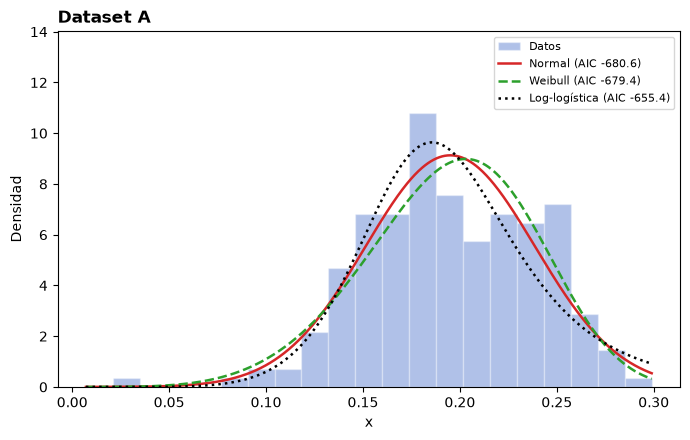

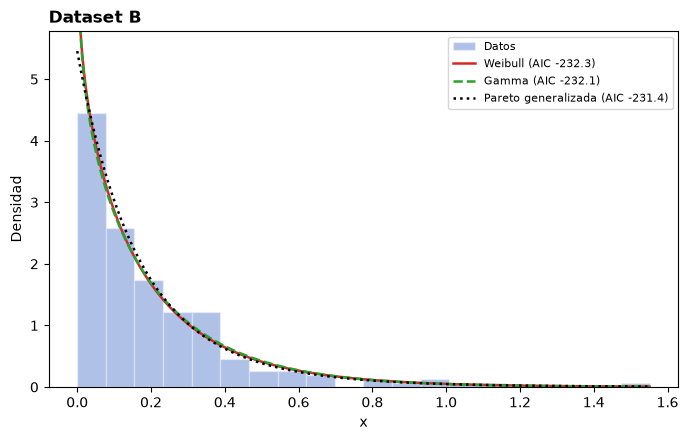

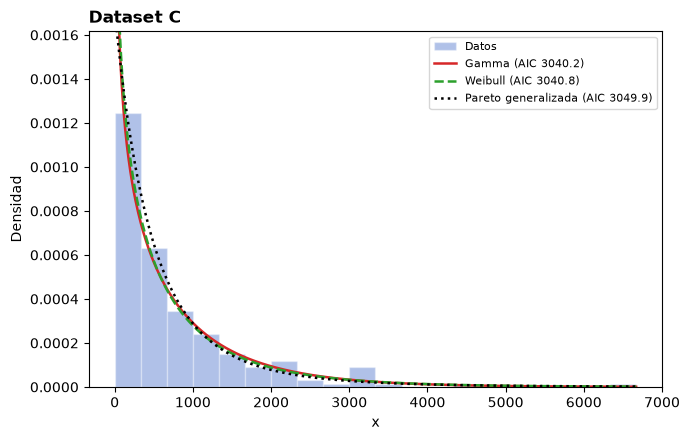

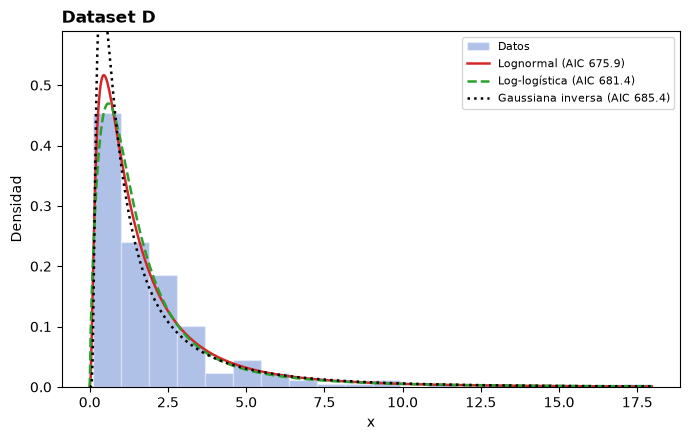

Distribución                     Parámetros        SSE  \
Dataset A 0               Normal         mu=0.195, sigma=0.0437     29.148   
          1              Weibull    c=5.071, loc=0, scale=0.212     32.427   
          2        Log-logística   c=7.293, loc=0, scale=0.1927     33.418   
Dataset B 0              Weibull  c=0.9095, loc=0, scale=0.1963    0.27619   
          1                Gamma  a=0.8636, loc=0, scale=0.2378    0.31577   
          2  Pareto generalizada  c=0.1083, loc=0, scale=0.1833    0.28803   
Dataset C 0                Gamma    a=0.7062, loc=0, scale=1080 4.4932e-08   
          1              Weibull     c=0.8007, loc=0, scale=676 2.5238e-08   
          2  Pareto generalizada   c=0.2453, loc=0, scale=583.7 1.1109e-08   
Dataset D 0            Lognormal    s=1.019, loc=0, scale=1.273  0.0069135   
          1        Log-logística     c=1.705, loc=0, scale=1.31  0.0060111   
          2    Gaussiana inversa   mu=1.763, loc=0, scale=1.169   0.025487   

                AIC     BIC     KS D  
Dataset A 0 -680.59 -673.99 0.052264  
          1 -679.36 -672.76 0.068452  
          2 -655.44 -648.85 0.058655  
Dataset B 0 -232.26 -225.67 0.034946  
          1  -232.1  -225.5 0.036079  
          2 -231.39  -224.8  0.04966  
Dataset C 0  3040.2  3046.8 0.038767  
          1  3040.8  3047.4  0.03675  
          2  3049.9  3056.5 0.057742  
Dataset D 0  675.89  682.49 0.053736  
          1   681.4     688 0.050821  
          2   685.4     692 0.092331

In [7]:
COLORES = ['#d62728', '#2ca02c', '#000000']
ESTILOS = ['-', '--', ':']

def top3(k):
    return ajustes[k].sort_values('AIC').head(3)

def plot_top3(ax, k):
    x = datos[k]
    alturas, _, _ = ax.hist(x, bins=20, density=True, color='#1f4fbf', alpha=0.35, edgecolor='white', label='Datos')
    malla = np.linspace(max(x.min() - 0.05 * np.ptp(x), 1e-9 if x.min() > 0 else x.min()), x.max(), 600)
    for (_, fila), color, estilo in zip(top3(k).iterrows(), COLORES, ESTILOS):
        dist = CANDIDATAS[fila['Distribución']][0]
        ax.plot(malla, dist.pdf(malla, *fila['params']), color=color, ls=estilo, lw=1.8,
                label=f"{fila['Distribución']} (AIC {fila['AIC']:.1f})")
    ax.set_title(f'Dataset {k}', loc='left', fontweight='bold')
    # Las densidades con forma < 1 tienden a infinito en 0; se recorta el eje para ver el histograma
    ax.set_ylim(0, 1.3 * alturas.max())
    ax.set_xlabel('x'); ax.set_ylabel('Densidad'); ax.legend(fontsize=8)

for k in NOMBRES:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    plot_top3(ax, k)
    fig.tight_layout(); fig.savefig(FIGURAS / f'top3_dataset_{k}.png', dpi=160); plt.show()

fig, axs = plt.subplots(2, 2, figsize=(12, 8.5))
for ax, k in zip(axs.flat, NOMBRES):
    plot_top3(ax, k)
fig.tight_layout(); fig.savefig(FIGURAS / 'top3_todos.png', dpi=160); plt.close(fig)

resumen = pd.concat({f'Dataset {k}': top3(k)[['Distribución', 'Parámetros', 'SSE', 'AIC', 'BIC', 'KS D']]
                     .reset_index(drop=True) for k in NOMBRES})
resumen.to_csv(RESULTADOS / 'top3.csv')
resumen

### Gráficas Q-Q de la mejor distribución
Complementan el histograma: si el modelo es bueno, los puntos siguen la diagonal, también en
las colas.

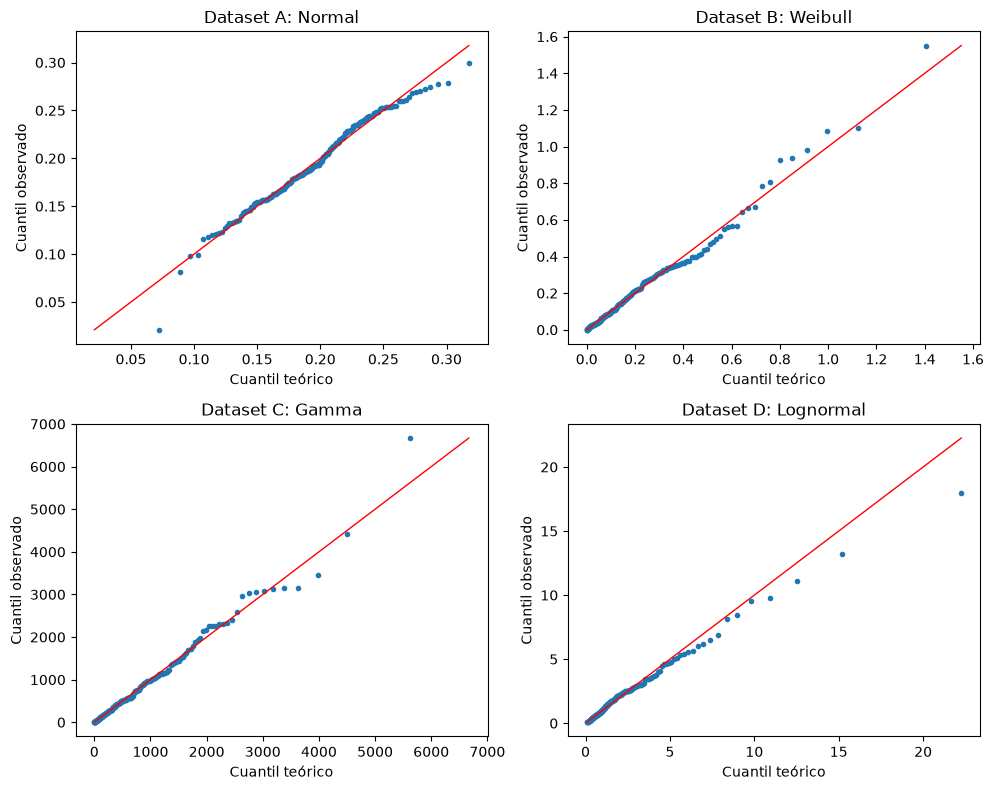

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
for ax, k in zip(axs.flat, NOMBRES):
    x = np.sort(datos[k]); n = len(x)
    mejor = top3(k).iloc[0]
    dist = CANDIDATAS[mejor['Distribución']][0]
    teoricos = dist.ppf((np.arange(1, n + 1) - 0.5) / n, *mejor['params'])
    ax.plot(teoricos, x, 'o', ms=3)
    lim = [min(teoricos.min(), x.min()), max(teoricos.max(), x.max())]
    ax.plot(lim, lim, 'r-', lw=1)
    ax.set_title(f"Dataset {k}: {mejor['Distribución']}")
    ax.set_xlabel('Cuantil teórico'); ax.set_ylabel('Cuantil observado')
fig.tight_layout(); fig.savefig(FIGURAS / 'qq_mejor.png', dpi=160); plt.show()

### Dataset C por mitades
El análisis del punto 5.2 indica que C no es estacionario: la media de la segunda mitad casi
triplica la de la primera. Ajustar una sola distribución a los 200 datos mezcla dos regímenes.
Como verificación se repite el ajuste en cada mitad.

In [9]:
mitades = {}
for nombre, x in [('C primera mitad', datos['C'][:100]), ('C segunda mitad', datos['C'][100:])]:
    t = tabla_ajuste(x)
    mitades[nombre] = t.sort_values('AIC').head(3)[['Distribución', 'Parámetros', 'AIC', 'BIC', 'KS D']].reset_index(drop=True)
    print(nombre, f'media = {x.mean():.4g}')
tabla_mitades = pd.concat(mitades)
tabla_mitades.to_csv(RESULTADOS / 'top3_C_mitades.csv')
tabla_mitades

C primera mitad media = 417.6
C segunda mitad media = 1107


Distribución                    Parámetros    AIC  \
C primera mitad 0              Weibull   c=0.717, loc=0, scale=335.4 1388.7   
                1                Gamma  a=0.6094, loc=0, scale=685.1 1390.9   
                2  Pareto generalizada  c=0.4957, loc=0, scale=232.8 1393.2   
C segunda mitad 0                Gamma   a=1.205, loc=0, scale=918.7 1603.9   
                1          Exponencial             loc=0, scale=1107 1603.9   
                2              Weibull    c=1.109, loc=0, scale=1152 1604.2   

                     BIC     KS D  
C primera mitad 0 1393.9 0.046238  
                1 1396.1 0.061856  
                2 1398.4 0.067027  
C segunda mitad 0 1609.1 0.054734  
                1 1606.5 0.088589  
                2 1609.4 0.055164